# Herbicide-trait shifts in seed sales

Soybean seed is sold with stacked herbicide-tolerance traits, and growers pick a **weed-control system**
along with the seed: dicamba-tolerant, 2,4-D-tolerant, glufosinate, or glyphosate only. Regulatory and
weed-resistance news can move that choice quickly. The question: **how is each system's share of seed sales
shifting, and where is it shifting fastest?**

Three steps:

1. Map every seed-trait code to the herbicide systems it carries, using a small trait matrix.
2. Roll bags up by state, crop, and crop year.
3. Compute each system's share and its year-over-year change, then map it.

> **About the data.** The original used retail point-of-sale seed transactions with branch locations as the
> geography. Trait codes, volumes, and trends here are **simulated** with generic trait labels. The trait-matrix
> join, rollups, and share math follow the original, with two calculation fixes noted below.

In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

pd.set_option("display.width", 130)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
STATES_URL = "https://www2.census.gov/geo/tiger/GENZ2023/shp/cb_2023_us_state_20m.zip"
REGION = ["ND", "SD", "NE", "KS", "MN", "IA", "MO", "WI", "IL", "IN", "OH", "MI", "AR", "KY", "TN"]
states = gpd.read_file(STATES_URL).query("STUSPS in @REGION").to_crs(4326)
SYSTEM_COLORS = {"Dicamba only": "#c0504d", "2,4-D only": "#3b6ea8", "Both (stacked)": "#8e44ad",
                 "Neither": "#bbbbbb"}

## 1. Trait matrix and simulated sales

The trait matrix flags which herbicide tolerances each trait code carries. One code, `GT-DT-24D-LL`,
carries **both** dicamba and 2,4-D tolerance. It's new, small, and growing, and it's exactly the kind of row
that breaks naive share math.

In [2]:
trait_matrix = pd.DataFrame([
    # trait code       glyphosate  glufosinate  dicamba  2,4-D
    ("CONV",              0,          0,          0,       0),
    ("GT",                1,          0,          0,       0),
    ("LL",                0,          1,          0,       0),
    ("GT-LL",             1,          1,          0,       0),
    ("GT-DT",             1,          0,          1,       0),
    ("GT-DT-LL",          1,          1,          1,       0),
    ("GT-24D-LL",         1,          1,          0,       1),
    ("GT-DT-24D-LL",      1,          1,          1,       1),
], columns=["seed_trait", "glyphosate", "glufosinate", "dicamba", "d24"])
trait_matrix

,seed_trait,glyphosate,glufosinate,dicamba,d24
0,CONV,0,0,0,0
1,GT,1,0,0,0
2,LL,0,1,0,0
3,GT-LL,1,1,0,0
4,GT-DT,1,0,1,0
5,GT-DT-LL,1,1,1,0
6,GT-24D-LL,1,1,0,1
7,GT-DT-24D-LL,1,1,1,1


In [3]:
rng = np.random.default_rng(8)
YEARS = [2023, 2024, 2025, 2026]
# soybean trait mix by year (national), then nudged per state
SOY_MIX = {
    2023: {"GT-DT": 0.22, "GT-DT-LL": 0.33, "GT-24D-LL": 0.33, "GT": 0.05, "LL": 0.03, "CONV": 0.04, "GT-DT-24D-LL": 0.0},
    2024: {"GT-DT": 0.17, "GT-DT-LL": 0.29, "GT-24D-LL": 0.42, "GT": 0.05, "LL": 0.03, "CONV": 0.04, "GT-DT-24D-LL": 0.0},
    2025: {"GT-DT": 0.13, "GT-DT-LL": 0.27, "GT-24D-LL": 0.46, "GT": 0.04, "LL": 0.03, "CONV": 0.04, "GT-DT-24D-LL": 0.03},
    2026: {"GT-DT": 0.09, "GT-DT-LL": 0.25, "GT-24D-LL": 0.47, "GT": 0.04, "LL": 0.03, "CONV": 0.04, "GT-DT-24D-LL": 0.08},
}
CORN_MIX = {"GT-LL": 0.62, "GT": 0.18, "GT-24D-LL": 0.12, "CONV": 0.08}
# states where growers lean on dicamba (resistant waterhemp/Palmer pressure) shift more slowly
DT_LEAN = {"AR": 0.18, "MO": 0.12, "TN": 0.12, "KY": 0.08, "IL": 0.06, "KS": 0.05, "IN": 0.03, "NE": 0.0, "IA": -0.02,
           "OH": 0.0, "MI": -0.04, "WI": -0.06, "MN": -0.08, "SD": -0.05, "ND": -0.1}
SPEED = {s: rng.uniform(0.6, 1.5) for s in REGION}

rows = []
for st in REGION:
    for n_branch in range(rng.integers(6, 18)):
        branch = f"{st}-B{n_branch:02d}"
        size = rng.lognormal(0, 0.6)
        for year in YEARS:
            base = SOY_MIX[2023]
            mix = {k: base[k] + (SOY_MIX[year][k] - base[k]) * SPEED[st] for k in base}
            mix["GT-DT"] += DT_LEAN[st] * 0.4
            mix["GT-DT-LL"] += DT_LEAN[st] * 0.6
            mix["GT-24D-LL"] -= DT_LEAN[st]
            mix = {k: max(v, 0.002) for k, v in mix.items()}
            tot = sum(mix.values())
            for crop, crop_mix, units, price in [("Soybeans", {k: v / tot for k, v in mix.items()}, 2200, 58),
                                                 ("Corn", CORN_MIX, 1500, 290)]:
                for trait, share in crop_mix.items():
                    bags = size * units * share * rng.lognormal(0, 0.15)
                    if bags < 1:
                        continue
                    rows.append({"branch": branch, "state": st, "crop": crop, "crop_year": year, "seed_trait": trait,
                                 "uom": "SSU" if crop == "Soybeans" else "80K", "transactions": int(bags / 40) + 1,
                                 "bags": round(bags), "revenue": round(bags * price * rng.uniform(0.95, 1.05), 2)})
sales = pd.DataFrame(rows)

In [4]:
print(f"{len(sales):,} branch x trait x year rows; {sales.branch.nunique()} branches in {sales.state.nunique()} states")
sales.head()

8,313 branch x trait x year rows; 189 branches in 15 states


,branch,state,crop,crop_year,seed_trait,uom,transactions,bags,revenue
0,ND-B00,ND,Soybeans,2023,GT-DT,SSU,12,478,28018.79
1,ND-B00,ND,Soybeans,2023,GT-DT-LL,SSU,14,552,33349.57
2,ND-B00,ND,Soybeans,2023,GT-24D-LL,SSU,24,957,54767.66
3,ND-B00,ND,Soybeans,2023,GT,SSU,3,113,6234.27
4,ND-B00,ND,Soybeans,2023,LL,SSU,2,62,3554.41


## 2. Join the trait matrix and classify each sale

The original sliced the data once per trait flag, aggregated each slice, then full-joined the slices back
together (using `globals()` to name them). A long-format table does the same job in one pass: join the
flags, then classify each row into exactly one **herbicide system**:

- **Dicamba only**: dicamba-tolerant, not 2,4-D
- **2,4-D only**: 2,4-D-tolerant, not dicamba
- **Both (stacked)**: tolerant to both
- **Neither**: glyphosate, glufosinate, or conventional only

In [5]:
df = sales.merge(trait_matrix, on="seed_trait", how="left", validate="many_to_one")
assert df.dicamba.notna().all(), "trait code missing from the trait matrix"
df["system"] = np.select([(df.dicamba == 1) & (df.d24 == 1), df.dicamba == 1, df.d24 == 1],
                         ["Both (stacked)", "Dicamba only", "2,4-D only"], default="Neither")

by = df.groupby(["state", "crop", "crop_year", "system"], as_index=False).agg(bags=("bags", "sum"))
by["share"] = by.bags / by.groupby(["state", "crop", "crop_year"]).bags.transform("sum")
by.head(8)

,state,crop,crop_year,system,bags,share
0,AR,Corn,2023,"2,4-D only",2977,0.120933
1,AR,Corn,2023,Neither,21640,0.879067
2,AR,Corn,2024,"2,4-D only",3008,0.117808
3,AR,Corn,2024,Neither,22525,0.882192
4,AR,Corn,2025,"2,4-D only",2985,0.118012
5,AR,Corn,2025,Neither,22309,0.881988
6,AR,Corn,2026,"2,4-D only",3117,0.124372
7,AR,Corn,2026,Neither,21945,0.875628


## 3. Two calculation fixes

**Shares that add up.** The original computed `dicamba bags / (dicamba bags + 2,4-D bags)`. A stacked
`GT-DT-24D-LL` bag lands in *both* slices, so it's counted twice in the denominator, and glyphosate-only
and conventional bags are ignored entirely. Here every bag belongs to exactly one system, and shares are
out of **all** soybean bags.

**Year-over-year change within each state.** The original took `lag()` over a window ordered by state,
crop, and year **with no partition**, so the first year of one state was compared with the last year of the
previous state. A `CROP_YEAR > 2023` guard hid this, but only as long as every state has 2023 data.
Grouping by state and crop fixes it for good.

In [6]:
soy = by[by.crop == "Soybeans"]

# original-style ratio, for comparison: stacked bags counted in both numerator slices
flags = df[df.crop == "Soybeans"].groupby(["crop_year"]).apply(lambda d: pd.Series({
    "dicamba_bags": d.loc[d.dicamba == 1, "bags"].sum(), "d24_bags": d.loc[d.d24 == 1, "bags"].sum(),
    "all_bags": d.bags.sum()}), include_groups=False)
compare = pd.DataFrame({
    "original: DT / (DT + 2,4-D)": flags.dicamba_bags / (flags.dicamba_bags + flags.d24_bags),
    "original: 2,4-D / (DT + 2,4-D)": flags.d24_bags / (flags.dicamba_bags + flags.d24_bags),
    "fixed: any dicamba / all bags": flags.dicamba_bags / flags.all_bags,
    "fixed: any 2,4-D / all bags": flags.d24_bags / flags.all_bags,
})
compare.style.format("{:.1%}")

,"original: DT / (DT + 2,4-D)","original: 2,4-D / (DT + 2,4-D)",fixed: any dicamba / all bags,"fixed: any 2,4-D / all bags"
crop_year,,,,
2023,64.6%,35.4%,57.0%,31.3%
2024,53.7%,46.3%,47.4%,40.8%
2025,47.2%,52.8%,43.6%,48.7%
2026,44.3%,55.7%,43.1%,54.1%


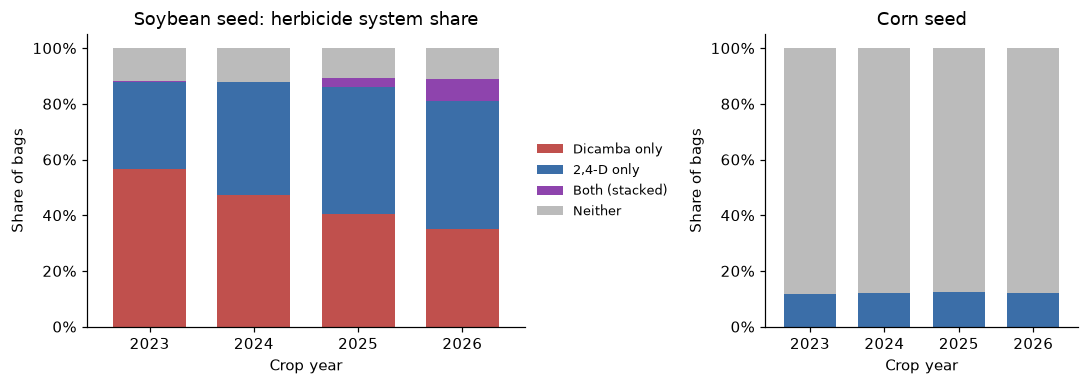

In [7]:
nat = soy.groupby(["crop_year", "system"]).bags.sum().unstack()
nat = nat.div(nat.sum(axis=1), axis=0)[list(SYSTEM_COLORS)]
corn = by[by.crop == "Corn"].groupby(["crop_year", "system"]).bags.sum().unstack()
corn = corn.div(corn.sum(axis=1), axis=0)[[c for c in SYSTEM_COLORS if c in corn]]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw={"width_ratios": [1.4, 1]})
nat.plot(kind="bar", stacked=True, ax=axes[0], color=[SYSTEM_COLORS[c] for c in nat.columns], width=0.7)
corn.plot(kind="bar", stacked=True, ax=axes[1], color=[SYSTEM_COLORS[c] for c in corn.columns], width=0.7, legend=False)
for ax, title in zip(axes, ["Soybean seed: herbicide system share", "Corn seed"]):
    ax.set(title=title, xlabel="Crop year", ylabel="Share of bags")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.tick_params(axis="x", rotation=0)
axes[0].legend(frameon=False, fontsize=8.5, loc="center left", bbox_to_anchor=(1.0, 0.5))
plt.tight_layout()

## 4. Year-over-year shift by state

In [8]:
dt = soy.assign(dt_share=np.where(soy.system.isin(["Dicamba only", "Both (stacked)"]), soy.share, 0)) \
        .groupby(["state", "crop_year"]).dt_share.sum().reset_index().sort_values(["state", "crop_year"])
dt["yoy_change"] = dt.groupby("state").dt_share.diff()           # lag within each state only
wide = dt.pivot(index="state", columns="crop_year", values="dt_share")
wide["change_23_26"] = wide[2026] - wide[2023]
wide.sort_values("change_23_26").head(15).style.format("{:.1%}")

crop_year,2023,2024,2025,2026,change_23_26
state,,,,,
TN,68.3%,56.9%,51.0%,47.0%,-21.4%
SD,49.5%,38.5%,33.2%,30.9%,-18.6%
MN,47.0%,33.6%,28.7%,28.4%,-18.5%
KS,62.2%,48.5%,43.3%,44.1%,-18.1%
IA,52.0%,45.4%,42.2%,38.7%,-13.3%
MO,67.4%,56.7%,54.6%,54.6%,-12.9%
ND,45.7%,37.6%,34.8%,33.1%,-12.6%
MI,51.8%,44.5%,40.7%,39.3%,-12.5%
IL,63.6%,52.9%,51.5%,51.5%,-12.1%


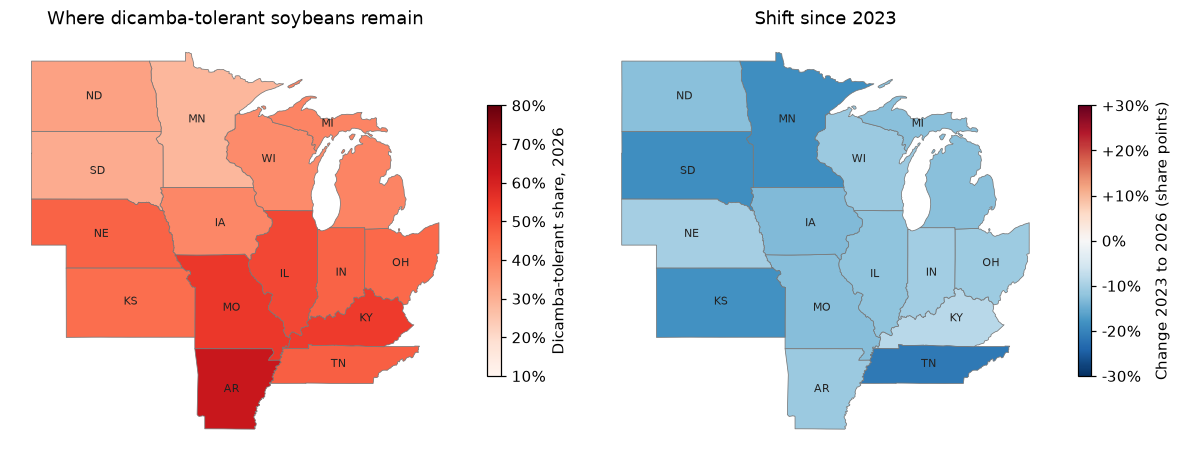

In [9]:
m = states.merge(wide, left_on="STUSPS", right_index=True)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
m.plot(ax=axes[0], column=2026, cmap="Reds", edgecolor="#777", lw=0.5, legend=True, vmin=0.1, vmax=0.8,
       legend_kwds={"label": "Dicamba-tolerant share, 2026", "shrink": 0.6})
m.plot(ax=axes[1], column="change_23_26", cmap="RdBu_r", edgecolor="#777", lw=0.5, legend=True, vmin=-0.3, vmax=0.3,
       legend_kwds={"label": "Change 2023 to 2026 (share points)", "shrink": 0.6})
for ax, title in zip(axes, ["Where dicamba-tolerant soybeans remain", "Shift since 2023"]):
    for r in m.itertuples():
        p = r.geometry.representative_point()
        ax.text(p.x, p.y, r.STUSPS, fontsize=7.5, ha="center", va="center", color="#222")
    ax.set_axis_off()
    ax.set_title(title)
fig.axes[2].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
fig.axes[3].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.0%}" if v else "0%"))
plt.tight_layout()

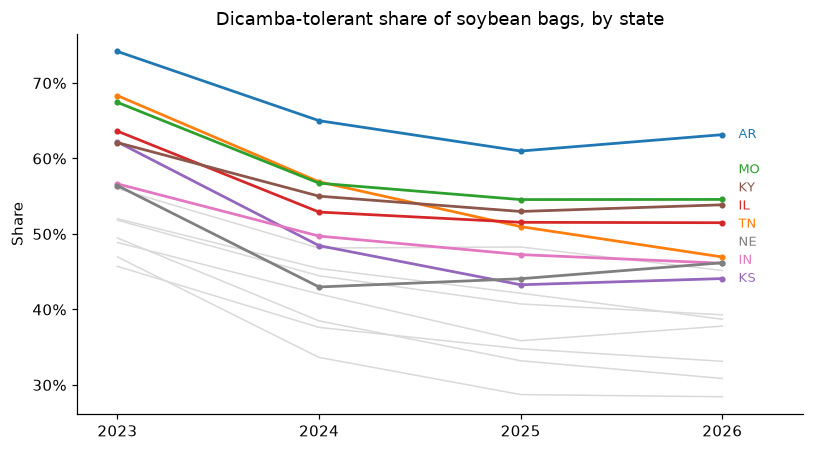

In [10]:
show = wide.sort_values(2023, ascending=False).index[:8]
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for st in wide.index:
    ax.plot([2023, 2024, 2025, 2026], wide.loc[st, [2023, 2024, 2025, 2026]], color="#d9d9d9", lw=1, zorder=1)
label_y = wide.loc[show, 2026].sort_values()
for i in range(1, len(label_y)):                      # nudge end labels apart so they don't overlap
    label_y.iloc[i] = max(label_y.iloc[i], label_y.iloc[i - 1] + 0.024)
for st in show:
    vals = wide.loc[st, [2023, 2024, 2025, 2026]]
    line, = ax.plot([2023, 2024, 2025, 2026], vals, lw=1.8, marker="o", ms=3)
    ax.text(2026.08, label_y[st], st, fontsize=8.5, va="center", color=line.get_color())
ax.set_xticks([2023, 2024, 2025, 2026])
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set(title="Dicamba-tolerant share of soybean bags, by state", ylabel="Share", xlim=(2022.8, 2026.4))
plt.tight_layout()

## 5. One more check: units

Corn and soybean seed ship in different units (80K-kernel units vs. seed-count units), so bag counts are
only summed **within** a crop. The original grouped by crop before summing, which kept this right, but it's
worth asserting, since a later change to the grouping would break it silently.

In [11]:
assert df.groupby("crop").uom.nunique().eq(1).all(), "mixed units within a crop"
df.groupby(["crop", "uom"]).agg(bags=("bags", "sum"), revenue=("revenue", "sum")).style.format("{:,.0f}")

,,bags,revenue
crop,uom,,
Corn,80K,"1,325,038","384,130,218"
Soybeans,SSU,"1,934,992","112,284,537"


## Takeaways

- **Classify, then share.** Mapping every sale to exactly one herbicide system makes shares add to 100% and
  handles stacked traits explicitly instead of double counting them.
- **Partition your lags.** A window without `partitionBy` quietly compares across groups. `groupby().diff()`
  in pandas, or `Window.partitionBy(...)` in Spark, keeps comparisons within each state and crop.
- **Long beats wide while computing.** One tidy table replaces per-trait slices stitched back together with
  full joins. Pivot wide only at the end, for display.
- **Assert the assumptions.** Trait codes missing from the matrix and mixed units both fail loudly here.

*Original: Snowflake SQL, PySpark on Databricks with a hand-maintained trait matrix. This version: pandas and
GeoPandas on simulated sales.*